In [1]:
import matplotlib.pyplot as plt

In [2]:
import pandas as pd

df = pd.read_excel("bitcoin market features table 10.xlxs.xlsx")

In [3]:
df[["trade_date", "close_price"]].head(10)

,trade_date,close_price
0,2015-10-13,249.507996
1,2016-05-31,531.385986
2,2020-06-22,9648.717773
3,2019-12-08,7564.345215
4,2020-02-11,10208.236330
5,2019-04-21,5314.531250
6,2022-08-14,24319.333980
7,2023-02-08,22939.398440
8,2024-06-02,67751.601560
9,2025-02-09,96500.093750


In [5]:
df["trade_date"] = pd.to_datetime(df["trade_date"])

In [6]:
df = df.sort_values("trade_date")

In [7]:
import numpy as np

In [8]:
df["year"] = df["trade_date"].dt.year

In [10]:
risk_return = (
    df.groupby("year")
      .agg(
          avg_return=("daily_return_pct", "mean"),
          avg_volatility=("volatility_30d", "mean")
      )
      .reset_index()
)

risk_return.head()

,year,avg_return,avg_volatility
0,2015,0.153104,3.348430
1,2016,0.251940,2.238689
2,2017,0.861178,4.461233
3,2018,-0.272904,4.084055
4,2019,0.241836,3.437973


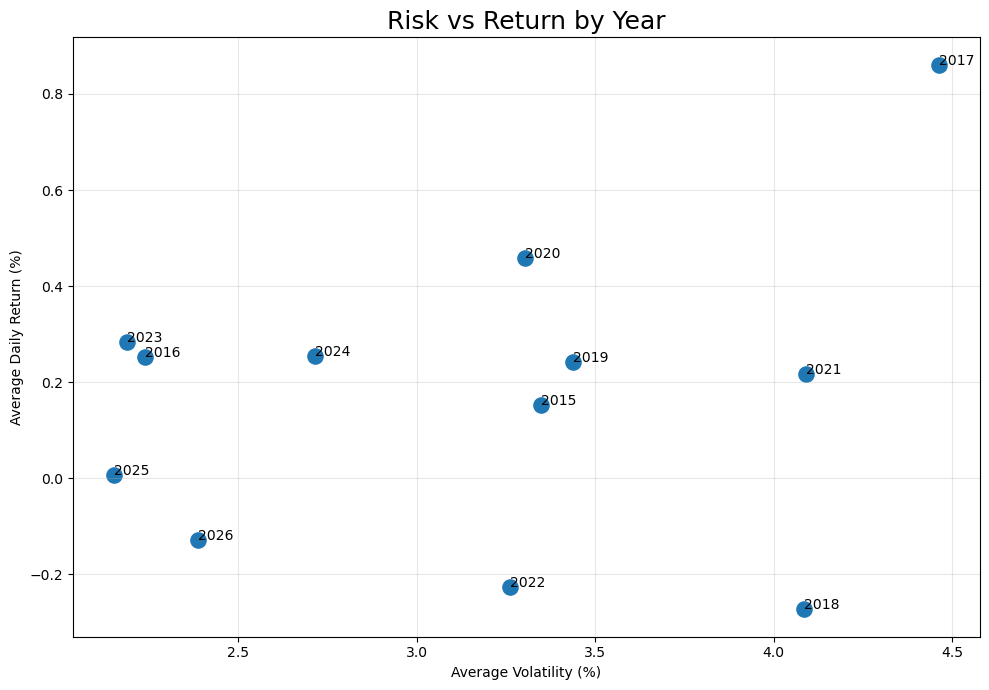

In [12]:
plt.figure(figsize=(10,7))

plt.scatter(
    risk_return["avg_volatility"],
    risk_return["avg_return"],
    s=120
)

for i in range(len(risk_return)):
    plt.text(
        risk_return["avg_volatility"].iloc[i],
        risk_return["avg_return"].iloc[i],
        risk_return["year"].iloc[i]
    )

plt.title("Risk vs Return by Year", fontsize=18)

plt.xlabel("Average Volatility (%)")

plt.ylabel("Average Daily Return (%)")

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()

In [13]:
sharpe = (
    df.groupby("year")
      .agg(
          avg_return=("daily_return_pct", "mean"),
          avg_volatility=("volatility_30d", "mean")
      )
      .reset_index()
)

sharpe["sharpe_ratio"] = (
    sharpe["avg_return"] /
    sharpe["avg_volatility"]
)

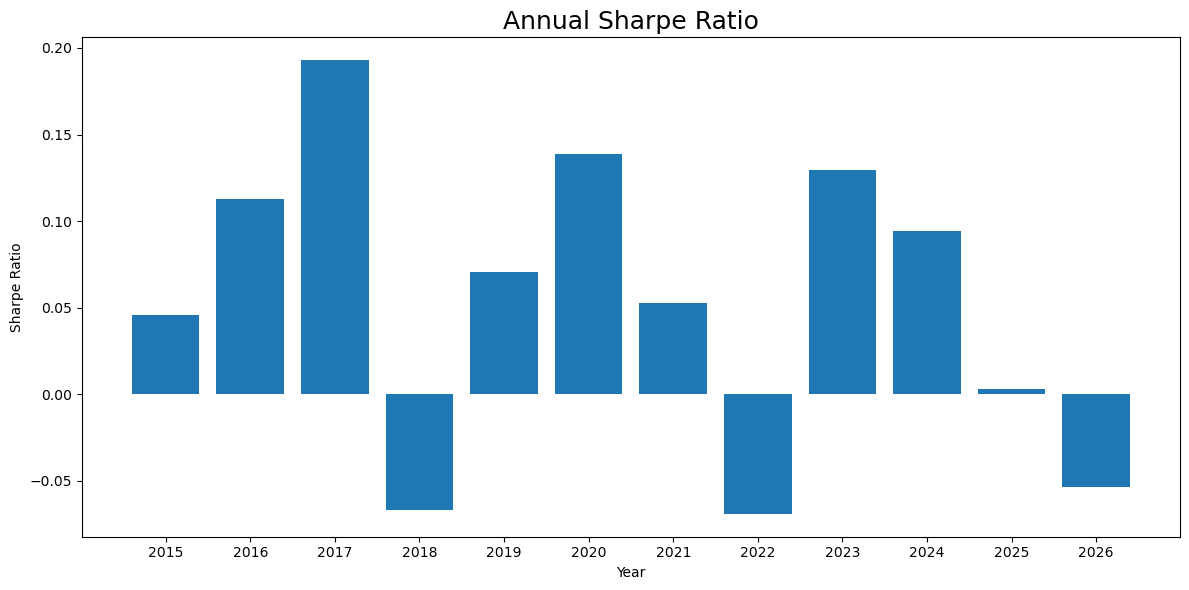

In [15]:
plt.figure(figsize=(12,6))

plt.bar(
    sharpe["year"].astype(str),
    sharpe["sharpe_ratio"]
)

plt.title("Annual Sharpe Ratio", fontsize=18)

plt.xlabel("Year")

plt.ylabel("Sharpe Ratio")

plt.tight_layout()

plt.show()

In [16]:
df["volatility_regime"] = pd.qcut(
    df["volatility_30d"],
    q=3,
    labels=["Low", "Medium", "High"]
)

In [17]:
df["volatility_regime"].value_counts()

volatility_regime
Medium    1404
Low       1394
High      1384
Name: count, dtype: int64

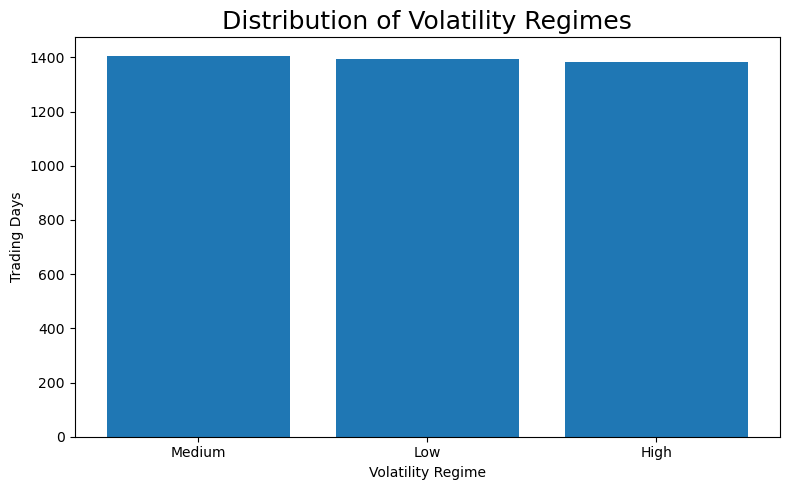

In [18]:
regime_counts = df["volatility_regime"].value_counts()

plt.figure(figsize=(8,5))

plt.bar(
    regime_counts.index.astype(str),
    regime_counts.values
)

plt.title("Distribution of Volatility Regimes", fontsize=18)

plt.xlabel("Volatility Regime")

plt.ylabel("Trading Days")

plt.tight_layout()

plt.show()

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_22024\4205339563.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby("volatility_regime")["daily_return_pct"]


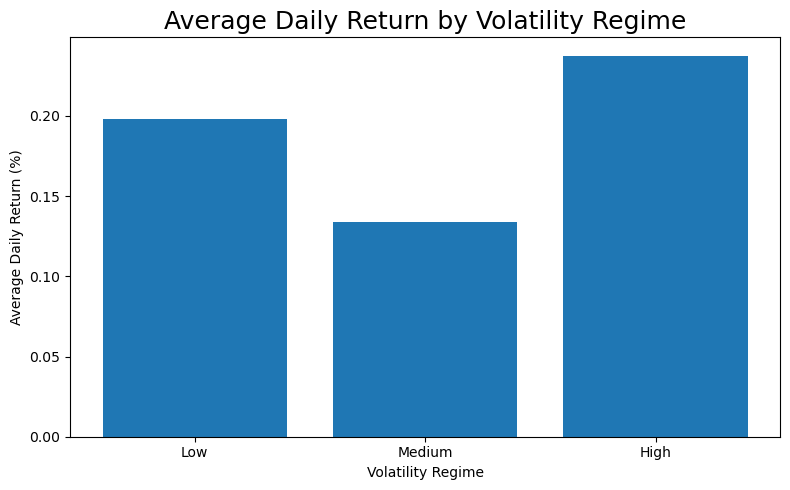

In [19]:
regime_return = (
    df.groupby("volatility_regime")["daily_return_pct"]
      .mean()
)

plt.figure(figsize=(8,5))

plt.bar(
    regime_return.index.astype(str),
    regime_return.values
)

plt.title("Average Daily Return by Volatility Regime", fontsize=18)

plt.xlabel("Volatility Regime")

plt.ylabel("Average Daily Return (%)")

plt.tight_layout()

plt.show()

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_22024\2808864451.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby("volatility_regime")["drawdown_pct"]


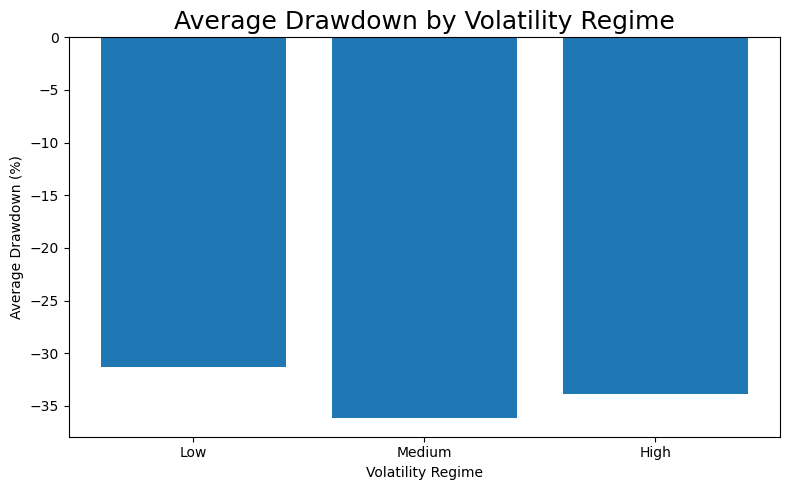

In [20]:
regime_drawdown = (
    df.groupby("volatility_regime")["drawdown_pct"]
      .mean()
)

plt.figure(figsize=(8,5))

plt.bar(
    regime_drawdown.index.astype(str),
    regime_drawdown.values
)

plt.title("Average Drawdown by Volatility Regime", fontsize=18)

plt.xlabel("Volatility Regime")

plt.ylabel("Average Drawdown (%)")

plt.tight_layout()

plt.show()

In [22]:
df["market_period"] = np.select(
    [
        (df["year"] >= 2015) & (df["year"] <= 2017),
        (df["year"] >= 2018) & (df["year"] <= 2020),
        (df["year"] >= 2021) & (df["year"] <= 2023),
        (df["year"] >= 2024)
    ],
    [
        "2015-2017",
        "2018-2020",
        "2021-2023",
        "2024-2026"
    ],
    default="Other"
)

In [24]:
period_summary = (
    df.groupby("market_period")
      .agg(
          avg_return=("daily_return_pct","mean"),
          avg_volatility=("volatility_30d","mean"),
          avg_drawdown=("drawdown_pct","mean"),
          avg_volume=("volume","mean")
      )
      .reset_index()
)

period_summary

,market_period,avg_return,avg_volatility,avg_drawdown,avg_volume
0,2015-2017,0.422164,3.348437,-13.010237,8.335496e+08
1,2018-2020,0.142637,3.607628,-55.815164,1.861893e+10
2,2021-2023,0.091114,3.180457,-45.587397,3.180665e+10
3,2024-2026,0.083155,2.424961,-17.680635,4.414139e+10


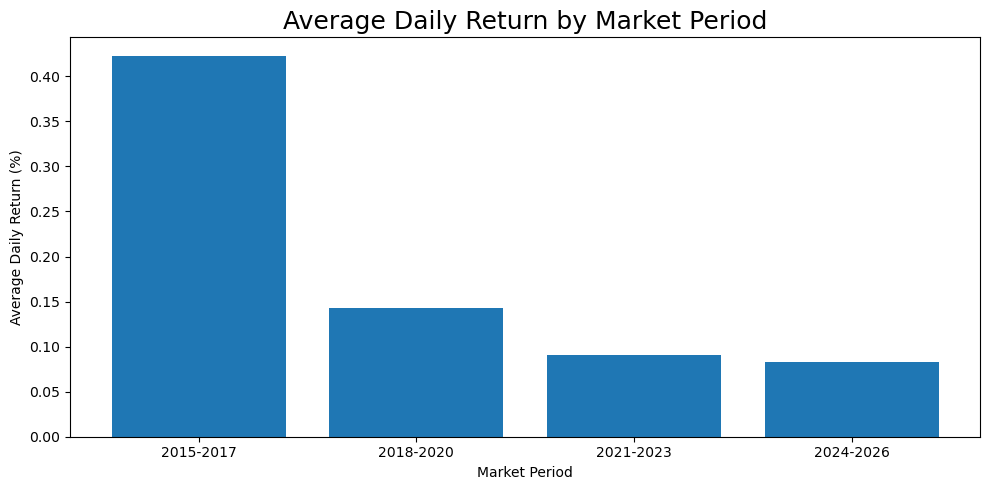

In [26]:
plt.figure(figsize=(10,5))

plt.bar(
    period_summary["market_period"],
    period_summary["avg_return"]
)

plt.title("Average Daily Return by Market Period", fontsize=18)

plt.xlabel("Market Period")

plt.ylabel("Average Daily Return (%)")

plt.tight_layout()

plt.show()

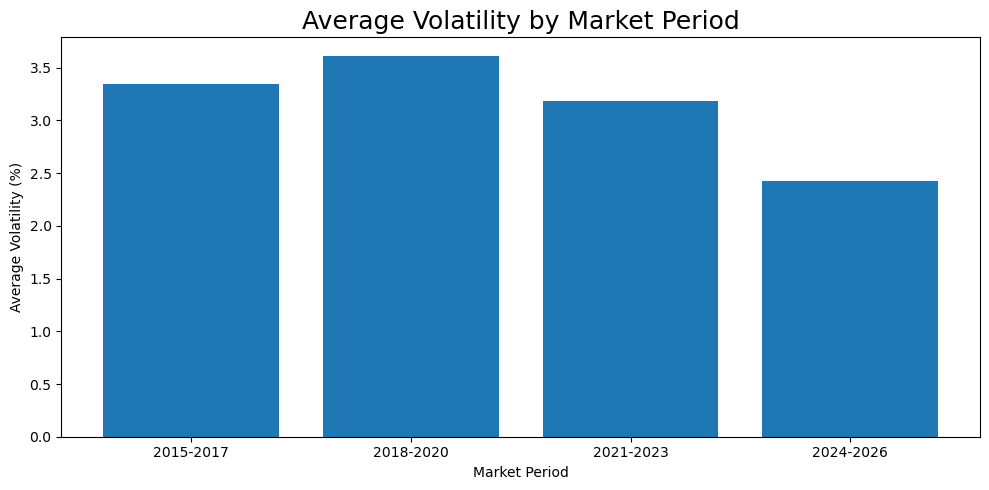

In [28]:
plt.figure(figsize=(10,5))

plt.bar(
    period_summary["market_period"],
    period_summary["avg_volatility"]
)

plt.title("Average Volatility by Market Period", fontsize=18)

plt.xlabel("Market Period")

plt.ylabel("Average Volatility (%)")

plt.tight_layout()

plt.show()

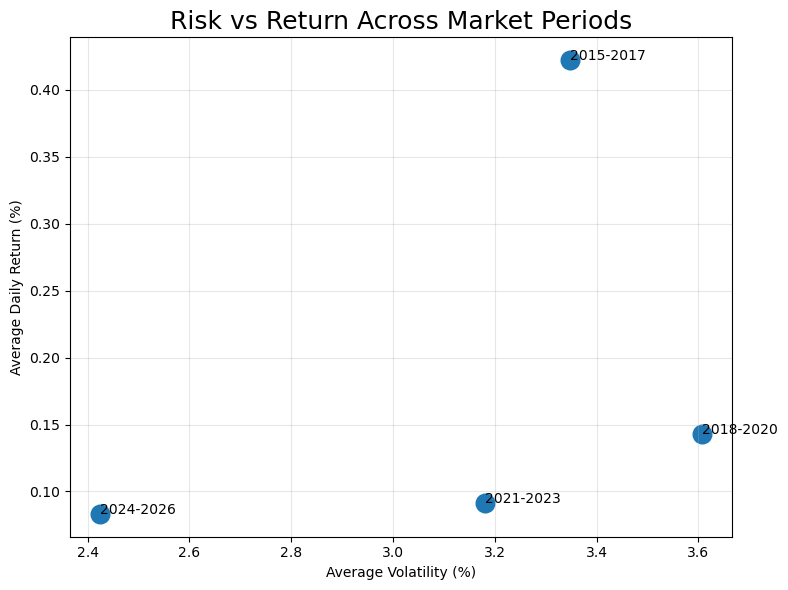

In [29]:
plt.figure(figsize=(8,6))

plt.scatter(
    period_summary["avg_volatility"],
    period_summary["avg_return"],
    s=180
)

for i in range(len(period_summary)):
    plt.text(
        period_summary["avg_volatility"].iloc[i],
        period_summary["avg_return"].iloc[i],
        period_summary["market_period"].iloc[i]
    )

plt.title("Risk vs Return Across Market Periods", fontsize=18)

plt.xlabel("Average Volatility (%)")

plt.ylabel("Average Daily Return (%)")

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()